In [1]:
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt

WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`
WARNING (pytensor.configdefaults): g++ not detected!  PyTensor will be unable to compile C-implementations and will default to Python. Performance may be severely degraded. To remove this warning, set PyTensor flags cxx to an empty string.
c:\VSC projects\neutrino_modeling\venv_dev\lib\site-packages\arviz\__init__.py:50: FutureWarning: 
ArviZ is undergoing a major refactor to improve flexibility and extensibility while maintaining a user-friendly interface.
Some upcoming changes may be backward incompatible.
For details and migration guidance, visit: https://python.arviz.org/en/latest/user_guide/migration_guide.html
  warn(


In [2]:
# Параметры детектора
R = 2.0
N = 40
r = 0.1
a = 0.5

# Параметры источника
Y = 10000
E = 1.0

# Число испускаемых фотонов
n_photons = int(Y * E)

# Геометрическая вероятность попадания фотона на ФЭУ
p_hit = N / 2 * (1 - np.cos(r / R))

print(f"Количество фотонов: {n_photons}")
print(f"Вероятность попадания: {p_hit:.6f}")

# Построение модели
with pm.Model() as detector_model:

    # Число фотонов, попавших на фотокатоды
    n_hits = pm.Binomial(
        "n_hits",
        n=n_photons,
        p=p_hit
    )

    # Полное число фотоэлектронов
    n_pe = pm.Poisson(
        "n_pe",
        mu=a * n_hits
    )

    # MCMC
    idata = pm.sample(
        draws=10000,
        tune=3000,
        chains=4,
        cores=1,
        step=pm.Metropolis(),
        random_seed=42,
        return_inferencedata=True
    )

Количество фотонов: 10000
Вероятность попадания: 0.024995


Sequential sampling (4 chains in 1 job)
CompoundStep
>Metropolis: [n_hits]
>Metropolis: [n_pe]


Output()

Sampling 4 chains for 3_000 tune and 10_000 draw iterations (12_000 + 40_000 draws total) took 30 seconds.


In [3]:
# Извлечение результатов MCMC
q_mcmc = idata.posterior["n_pe"].values.flatten()

print("Результаты моделирования в PyMC:")
print(f"Среднее число фотоэлектронов: {np.mean(q_mcmc):.3f}")
print(f"Стандартное отклонение: {np.std(q_mcmc, ddof=1):.3f}")

# Диагностика MCMC
print(az.summary(idata, var_names=["n_hits", "n_pe"]))

Результаты моделирования в PyMC:
Среднее число фотоэлектронов: 125.275
Стандартное отклонение: 13.596
           mean      sd  hdi_3%  hdi_97%  mcse_mean  mcse_sd  ess_bulk  \
n_hits  250.276  15.689   219.0    278.0      0.235    0.128    4440.0   
n_pe    125.275  13.596    98.0    149.0      0.201    0.117    4567.0   

        ess_tail  r_hat  
n_hits    7200.0    1.0  
n_pe      7123.0    1.0  


In [7]:
class Source:
    def __init__(self, Y=10000):
        self.Y = Y

    @staticmethod
    def _generate_directions_array(n):
        """
        Генерация n изотропных направлений фотонов.
        Возвращает массив размерности (n, 3).
        """
        phi = np.random.uniform(0, 2 * np.pi, n)
        cos_theta = np.random.uniform(-1, 1, n)

        sin_theta = np.sqrt(1 - cos_theta**2)

        return np.column_stack((
            sin_theta * np.cos(phi),
            sin_theta * np.sin(phi),
            cos_theta
        ))

    def generate_directions_array(self, E):
        """
        Генерация направлений для фиксированного числа фотонов.
        """
        if E < 0:
            raise ValueError("Энергия не может быть отрицательной.")

        n_photons = int(round(self.Y * E))

        return self._generate_directions_array(n_photons)

    def generate_directions(self, E, batch_size=100):
        """
        Генерация направлений порциями.
        Используется в версиях модели с последовательной обработкой порций.
        """
        if E < 0:
            raise ValueError("Энергия не может быть отрицательной.")

        if batch_size <= 0:
            raise ValueError("Размер порции должен быть положительным.")

        n_photons = int(round(self.Y * E))

        for start in range(0, n_photons, batch_size):
            n = min(batch_size, n_photons - start)

            yield self._generate_directions_array(n)

class Detector:
    def __init__(self, R=2, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a

        # Равномерное распределение ФЭУ на сфере
        indices = np.arange(N)

        z = 1 - 2 * (indices + 0.5) / N
        phi = np.pi * (3 - np.sqrt(5)) * indices

        rho = np.sqrt(1 - z**2)

        x = rho * np.cos(phi)
        y = rho * np.sin(phi)

        self.pm_positions = R * np.column_stack((x, y, z))

    def propagate_photons(
        self,
        directions,
        source_position,
        attenuation_length=None
    ):
        """
        Распространение фотонов и проверка попадания на ФЭУ.
        Возвращает булев массив попаданий и длины траекторий.
        """
        directions = np.asarray(directions, dtype=float)
        source_position = np.asarray(source_position, dtype=float)

        if directions.ndim != 2 or directions.shape[1] != 3:
            raise ValueError("Направления должны иметь размерность (N, 3).")

        if source_position.shape != (3,):
            raise ValueError("Координаты источника должны иметь размерность (3,).")

        if np.linalg.norm(source_position) > self.R:
            raise ValueError("Источник находится за пределами детектора.")

        if attenuation_length is not None and attenuation_length <= 0:
            raise ValueError("Длина поглощения должна быть положительной.")

        # Пустой массив фотонов
        if len(directions) == 0:
            return np.zeros(0, dtype=bool), np.zeros(0)

        # Пересечение лучей со сферой
        dot = directions @ source_position

        t = -dot + np.sqrt(
            dot**2
            + self.R**2
            - np.dot(source_position, source_position)
        )

        # Точки попадания на поверхность сферы
        hit_points = source_position + t[:, None] * directions

        # Проверка попадания на фотокатоды
        cos_angles = (
            (hit_points / self.R)
            @ (self.pm_positions / self.R).T
        )

        hits = np.max(cos_angles, axis=1) >= np.cos(self.r / self.R)

        # Учёт поглощения
        if attenuation_length is not None:
            survival_probability = np.exp(-t / attenuation_length)

            survived = (
                np.random.random(len(directions))
                < survival_probability
            )

            hits &= survived

        return hits, t

    def generate_photoelectrons(self, photon_hits):
        """
        Генерация полного числа фотоэлектронов.
        Каждый фотон, попавший на ФЭУ, создаёт Pois(a) фотоэлектронов.
        """
        if np.isscalar(photon_hits):
            n_hits = int(photon_hits)
        else:
            n_hits = np.count_nonzero(photon_hits)

        return np.random.poisson(self.a * n_hits)

    def simulate_event(
        self,
        source,
        E,
        source_position,
        attenuation_length=None
    ):
        """
        Моделирование одного события.
        Возвращает полное число фотоэлектронов.
        """
        directions = source.generate_directions_array(E)

        hits, t = self.propagate_photons(
            directions,
            source_position,
            attenuation_length
        )

        return self.generate_photoelectrons(hits)            

In [8]:
# Создаём детектор с параметрами из задач 1–4
detector = Detector(
    R=2.0,
    N=40,
    r=0.1,
    a=0.5
)

# Создаём источник
source = Source(Y=10000)

# Энергия и положение источника
E = 1.0
position = np.array([0.0, 0.0, 0.0])

# Массив результатов задачи 4
results = np.empty(n_events, dtype=int)

for i in range(n_events):
    results[i] = detector.simulate_event(
        source,
        E,
        position
    )

print("Количество смоделированных событий:", len(results))
print("Среднее число фотоэлектронов:", np.mean(results))
print("Стандартное отклонение:", np.std(results, ddof=1))

Количество смоделированных событий: 10000
Среднее число фотоэлектронов: 124.9832
Стандартное отклонение: 13.589156864148263


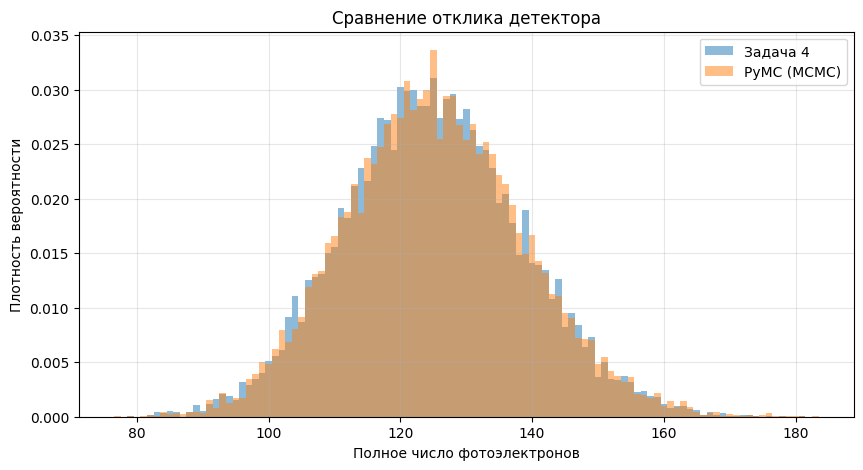

In [9]:
# Результаты задачи 4
q_task4 = np.asarray(results)

# Общие границы столбцов гистограмм
bins = np.arange(
    min(q_task4.min(), q_mcmc.min()) - 0.5,
    max(q_task4.max(), q_mcmc.max()) + 1.5,
    1
)

plt.figure(figsize=(10, 5))

plt.hist(
    q_task4,
    bins=bins,
    density=True,
    alpha=0.5,
    label="Задача 4"
)

plt.hist(
    q_mcmc,
    bins=bins,
    density=True,
    alpha=0.5,
    label="PyMC (MCMC)"
)

plt.xlabel("Полное число фотоэлектронов")
plt.ylabel("Плотность вероятности")
plt.title("Сравнение отклика детектора")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [10]:
print("Задача 4:")
print(f"Среднее: {np.mean(q_task4):.3f}")
print(f"Стандартное отклонение: {np.std(q_task4, ddof=1):.3f}")

print("\nPyMC (MCMC):")
print(f"Среднее: {np.mean(q_mcmc):.3f}")
print(f"Стандартное отклонение: {np.std(q_mcmc, ddof=1):.3f}")

Задача 4:
Среднее: 124.983
Стандартное отклонение: 13.589

PyMC (MCMC):
Среднее: 125.275
Стандартное отклонение: 13.596


Относительное расхождение средних значений составляет около 0.23%, а стандартные отклонения практически совпадают. Это свидетельствует о том, что вероятностная модель, реализованная в PyMC, хорошо воспроизводит статистические характеристики отклика детектора, полученные при непосредственном моделировании.